Saving image.jp2 to image.jp2


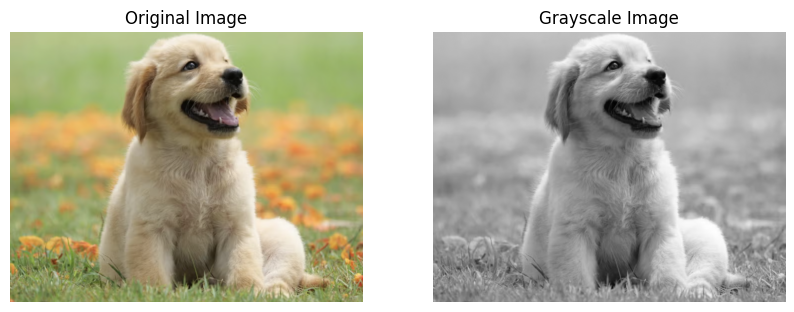

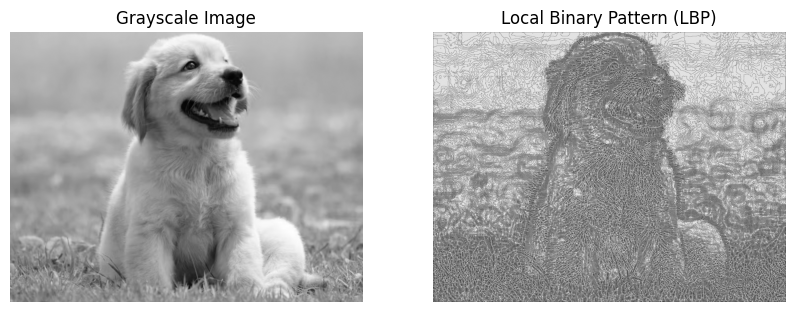

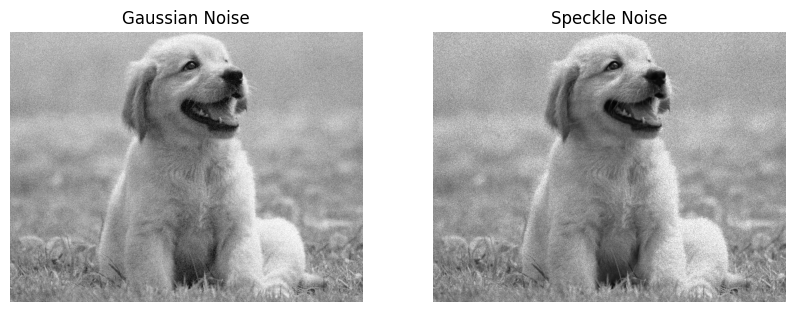

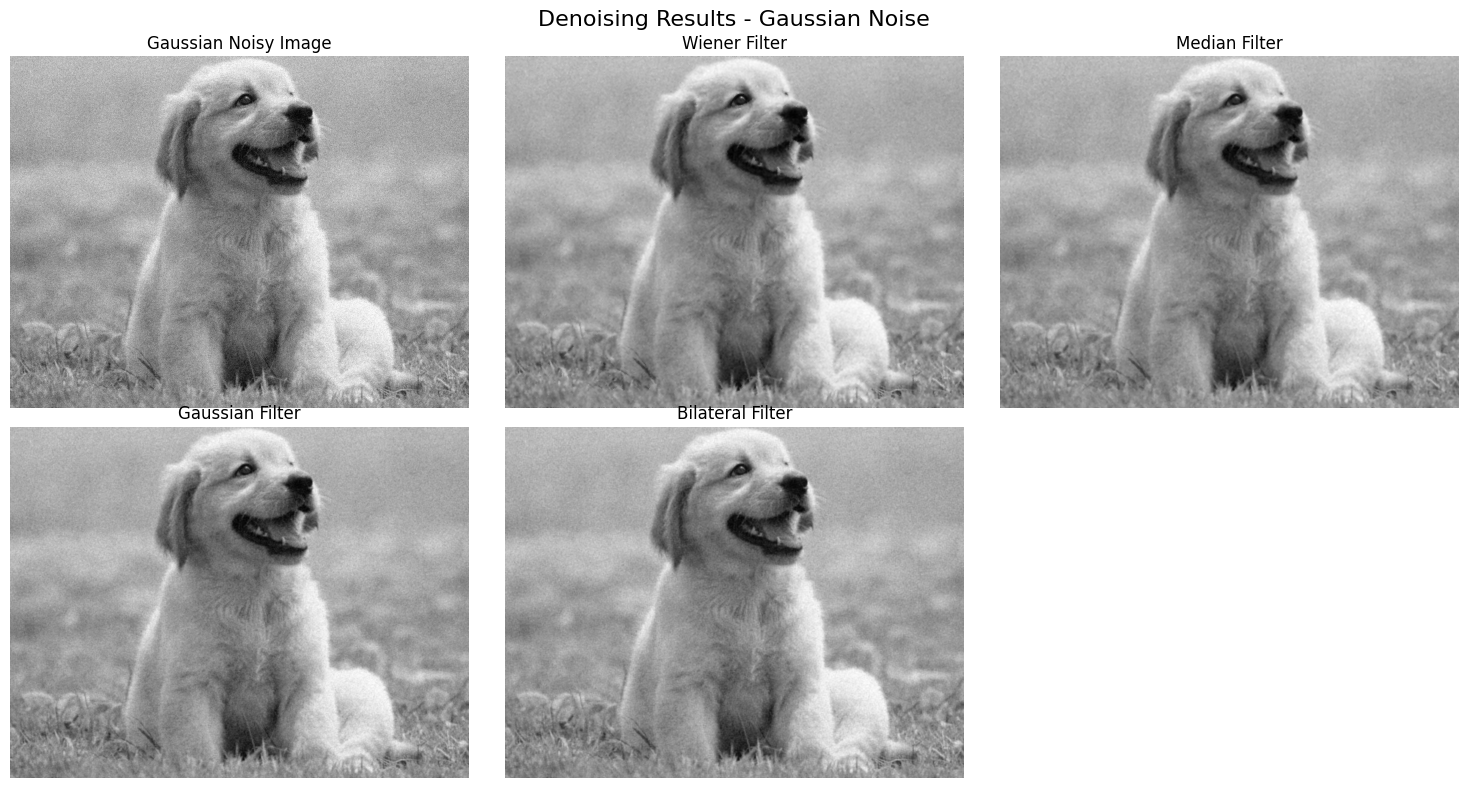

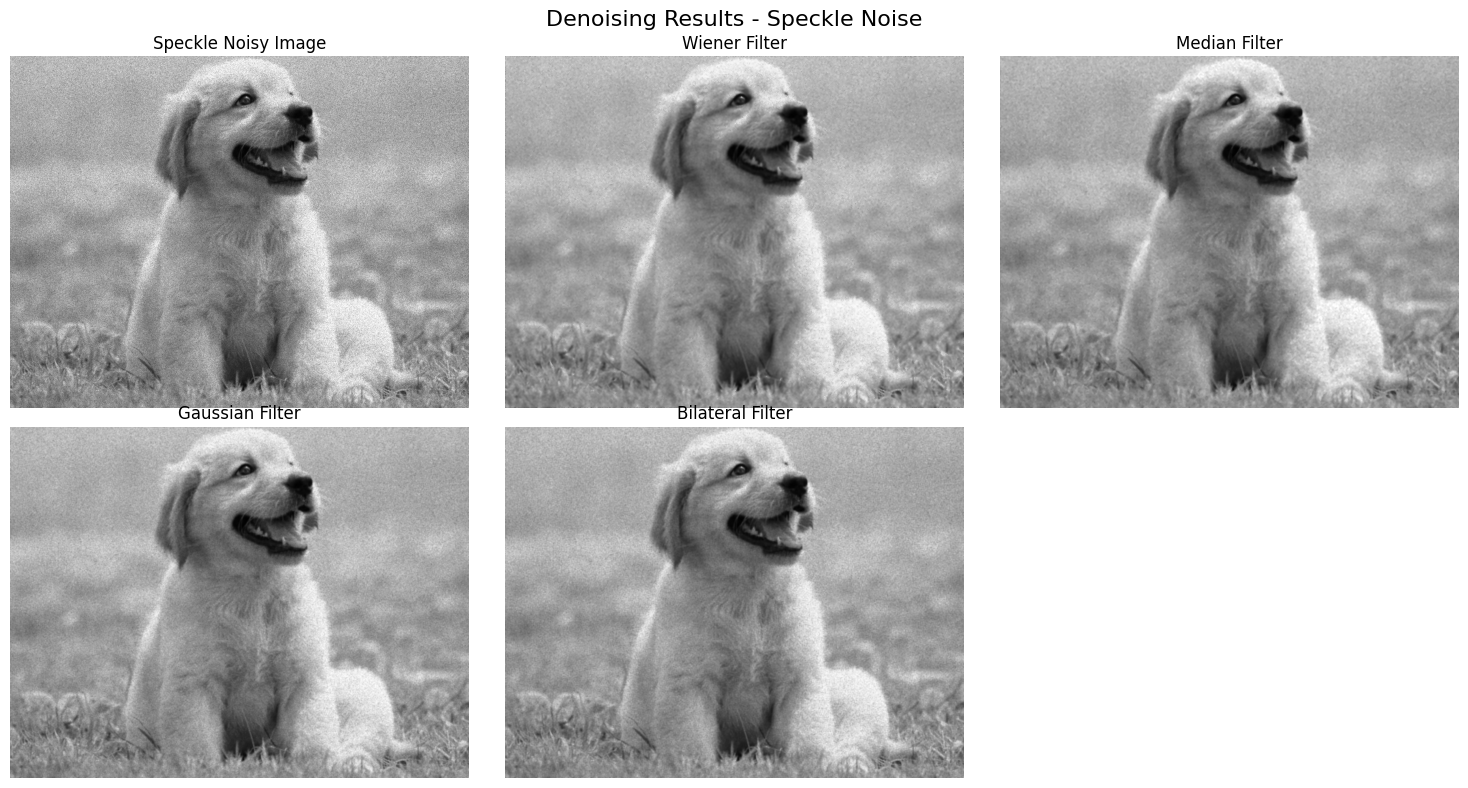

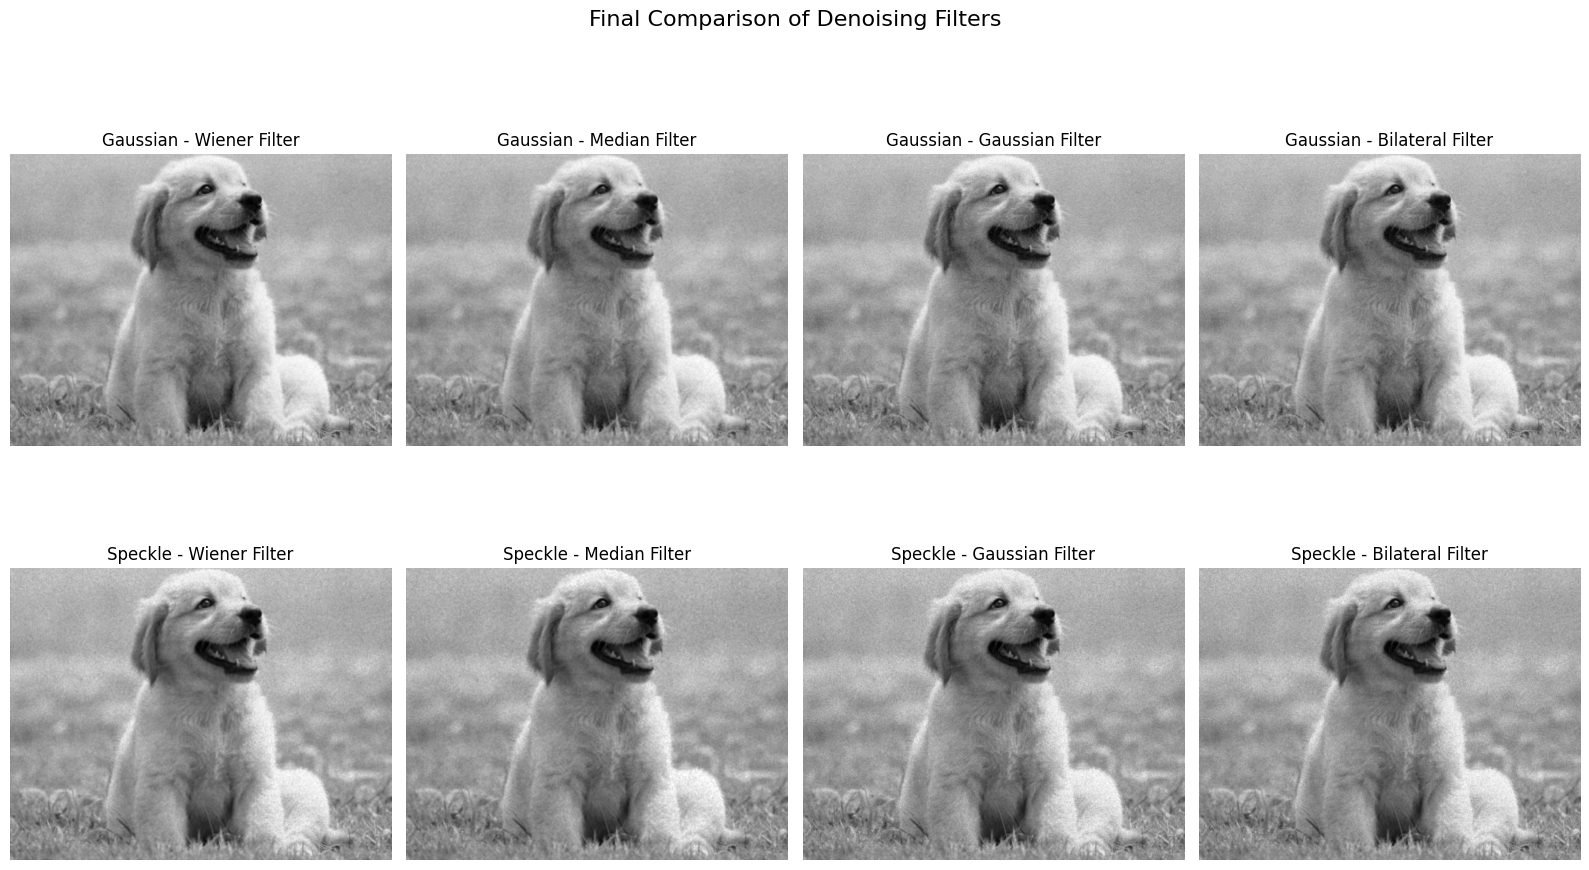

Assignment 9 Completed Successfully!


In [2]:

# ASSIGNMENT 9


!pip install scikit-image -q

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from scipy.signal import wiener
from skimage.feature import local_binary_pattern


# 1. UPLOAD IMAGE


uploaded = files.upload()

image_path = list(uploaded.keys())[0]
image = cv2.imread(image_path)

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


# 2. CONVERT IMAGE TO GRAYSCALE


gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(gray, cmap='gray')
plt.title("Grayscale Image")
plt.axis("off")

plt.show()


# 3. LOCAL BINARY PATTERN (LBP)


radius = 1
n_points = 8 * radius

lbp = local_binary_pattern(
    gray, n_points, radius, method='uniform'
)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(gray, cmap='gray')
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(lbp, cmap='gray')
plt.title("Local Binary Pattern (LBP)")
plt.axis("off")

plt.show()


# 4. ADD GAUSSIAN AND SPECKLE NOISE


img = gray.astype(np.float32) / 255.0

# Gaussian Noise
gaussian_noise = np.random.normal(0, 0.08, img.shape)
gaussian_noisy = np.clip(img + gaussian_noise, 0, 1)

# Speckle Noise
speckle_noise = np.random.normal(0, 0.15, img.shape)
speckle_noisy = np.clip(img + img * speckle_noise, 0, 1)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(gaussian_noisy, cmap='gray')
plt.title("Gaussian Noise")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(speckle_noisy, cmap='gray')
plt.title("Speckle Noise")
plt.axis("off")

plt.show()


# 5. DEFINE FOUR DENOISING FILTERS


def apply_filters(noisy_image):

    noisy_uint8 = (noisy_image * 255).astype(np.uint8)

    # (a) Wiener Filter - 5x5
    wiener_img = wiener(noisy_image, mysize=(5,5))
    wiener_img = np.clip(wiener_img, 0, 1)

    # (b) Median Filter - 5x5
    median_img = cv2.medianBlur(noisy_uint8, 5)

    # (c) Gaussian Filter - 5x5
    gaussian_img = cv2.GaussianBlur(
        noisy_uint8, (5,5), 1.0
    )

    # (d) Bilateral Filter
    bilateral_img = cv2.bilateralFilter(
        noisy_uint8, 5, 75, 75
    )

    return [
        wiener_img,
        median_img,
        gaussian_img,
        bilateral_img
    ]


# 6. APPLY FILTERS TO GAUSSIAN NOISY IMAGE


gaussian_results = apply_filters(gaussian_noisy)

filter_names = [
    "Wiener Filter",
    "Median Filter",
    "Gaussian Filter",
    "Bilateral Filter"
]

plt.figure(figsize=(15,8))

plt.subplot(2,3,1)
plt.imshow(gaussian_noisy, cmap='gray')
plt.title("Gaussian Noisy Image")
plt.axis("off")

for i in range(4):
    plt.subplot(2,3,i+2)
    plt.imshow(gaussian_results[i], cmap='gray')
    plt.title(filter_names[i])
    plt.axis("off")

plt.suptitle("Denoising Results - Gaussian Noise", fontsize=16)
plt.tight_layout()
plt.show()


# 7. APPLY FILTERS TO SPECKLE NOISY IMAGE


speckle_results = apply_filters(speckle_noisy)

plt.figure(figsize=(15,8))

plt.subplot(2,3,1)
plt.imshow(speckle_noisy, cmap='gray')
plt.title("Speckle Noisy Image")
plt.axis("off")

for i in range(4):
    plt.subplot(2,3,i+2)
    plt.imshow(speckle_results[i], cmap='gray')
    plt.title(filter_names[i])
    plt.axis("off")

plt.suptitle("Denoising Results - Speckle Noise", fontsize=16)
plt.tight_layout()
plt.show()


# 8. FINAL COMPARISON


plt.figure(figsize=(16,10))

for i in range(4):
    plt.subplot(2,4,i+1)
    plt.imshow(gaussian_results[i], cmap='gray')
    plt.title("Gaussian - " + filter_names[i])
    plt.axis("off")

for i in range(4):
    plt.subplot(2,4,i+5)
    plt.imshow(speckle_results[i], cmap='gray')
    plt.title("Speckle - " + filter_names[i])
    plt.axis("off")

plt.suptitle("Final Comparison of Denoising Filters", fontsize=16)
plt.tight_layout()
plt.show()

print("Assignment 9 Completed Successfully!")





